# P3: exploración de patrones de uso de estaciones

Notebook solo de exploración. La lógica final vive en `mi_bici_experiment/features.py` y `modeling/train.py` (`python -m mi_bici_experiment.modeling.train clustering-p3`).

Requiere haber corrido `python -m mi_bici_experiment.dataset` y `python -m mi_bici_experiment.features`.

In [1]:
# Carga de viajes válidos y perfil de entrenamiento
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from mi_bici_experiment.config import (DESTINO_COL, FECHA_FIN_COL, FECHA_INICIO, FECHA_INICIO_COL,
    FEATURES_PARQUET, P3_FIN_ENTRENAMIENTO, RANDOM_STATE, STATION_COL)
from mi_bici_experiment.features import columnas_perfil, filtrar_viajes_validos, perfil_estaciones

cols = [STATION_COL, DESTINO_COL, FECHA_INICIO_COL, FECHA_FIN_COL]
viajes = filtrar_viajes_validos(pd.read_parquet(FEATURES_PARQUET, columns=cols))
perfil = perfil_estaciones(viajes, FECHA_INICIO, P3_FIN_ENTRENAMIENTO)
print(f'{len(viajes):,} viajes válidos; {len(perfil)} estaciones con perfil')
perfil.describe().T[['mean', 'std', 'min', 'max']].tail(3)

2026-10-16 21:44:44.666 | INFO     | mi_bici_experiment.features:filtrar_viajes_validos:65 - P3: viajes descartados por duración o devolución: 142,898


4,354,979 viajes válidos; 378 estaciones con perfil


,mean,std,min,max
prop_fin_semana,0.212355,0.051347,0.071930,0.472083
log_viajes_dia,3.153353,0.785415,1.348026,5.457495
balance,-0.028319,0.117598,-0.396010,0.393229


## Forma del día

Perfil horario de salidas en días hábiles: hay estaciones con pico de mañana y otras con pico de tarde.

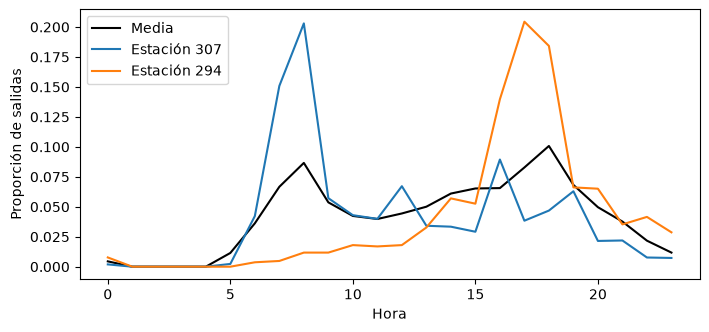

In [2]:
# Perfil horario medio y de dos estaciones contrastantes
sal = columnas_perfil(perfil, 'sal_h')
pico_manana = perfil.set_index('estacion_id')[sal[6:10]].sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(24), perfil[sal].mean().values, color='black', label='Media')
for e in [pico_manana.idxmax(), pico_manana.idxmin()]:
    ax.plot(range(24), perfil.set_index('estacion_id').loc[e, sal].values, label=f'Estación {e}')
ax.set_xlabel('Hora'); ax.set_ylabel('Proporción de salidas'); ax.legend(); plt.show()

## Reducción de dimensión

Las 48 proporciones horarias están correlacionadas y son ruidosas; se revisa cuánta varianza retienen los primeros componentes.

In [3]:
# Varianza explicada por PCA sobre el perfil estandarizado
X = StandardScaler().fit_transform(perfil[columnas_perfil(perfil)])
pca = PCA(random_state=RANDOM_STATE).fit(X)
print(np.round(np.cumsum(pca.explained_variance_ratio_)[:6], 3))

[0.172 0.263 0.329 0.377 0.423 0.456]


## Número de grupos

Silueta por k con 3 componentes. Los candidatos del modelo empiezan en k = 3: con k = 2 solo se separa mañana de tarde.

In [4]:
# Silueta para k = 2..8
Z = PCA(3, random_state=RANDOM_STATE).fit_transform(X)
for k in range(2, 9):
    etiquetas = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(Z)
    print(k, round(silhouette_score(Z, etiquetas, random_state=RANDOM_STATE), 3))

2 0.333
3 0.275


4 0.255
5 0.256
6 0.252
7 0.25
8 0.261


## Hallazgos

- Las estaciones se separan por la hora de su pico: origen matutino (vivienda) frente a destino matutino (oficinas y escuelas).
- Tres componentes retienen 33% de la varianza: conservan los picos de mañana y tarde y descartan ruido de horas con pocos viajes.
- Entre k = 3 y 8 la silueta es máxima en k = 3 (0.275); el candidato usa ese criterio y se compara contra k = 4 fijo.